# 03 · Limpieza de las señales importantes y extracción de eventos

**Capítulo 1 — Etapas 3, 4 y 5 del pipeline · Bloques D (espectro), E (antes/después) y F (movimiento) del EDA**

## ¿Qué hace este notebook?
1. **Espectro de las 10 señales** (crudas): muestra en qué frecuencias está la información y dónde está el ruido.
   Es la evidencia que justifica cada filtro.
2. **Limpia solo las 7 señales que van al modelo** (ECG, EDA pecho, respiración, BVP, EDA muñeca y las dos
   temperaturas) con los filtros estándar de la literatura.
3. **Extrae eventos**: picos R del ECG, latidos del BVP, componente tónico y respuestas (SCR) de la EDA,
   y respiraciones.
4. Calcula un **índice de movimiento** con los acelerómetros, que no predice estrés pero sirve para marcar artefactos.

## Los filtros (resumen)
| Señal | Filtro | Para qué | Fuente |
|---|---|---|---|
| ECG | notch 50 Hz + pasa-banda 0.5–40 Hz | quitar la red eléctrica, la deriva de línea base y el ruido muscular | Kligfield et al. 2007 |
| EDA pecho | pasa-bajas 5 Hz, luego a 8 Hz | quitar ruido rápido (la EDA cambia lento) | Schmidt et al. 2018 (WESAD) |
| EDA muñeca | pasa-bajas 1 Hz | ídem, para el E4 a 4 Hz | Boucsein et al. 2012 |
| Respiración | método Khodadad (NeuroKit2), a 32 Hz | quitar deriva y ruido | Khodadad et al. 2018 |
| BVP | método Elgendi (pasa-banda 0.5–8 Hz) | quitar deriva y ruido | Elgendi et al. 2013 |
| Temperatura | pasa-bajas 0.1 Hz, a 4 Hz | la temperatura cambia muy lento | — |

Todos son **de fase cero**: no desplazan los picos en el tiempo.

**Nota:** la red eléctrica es de **50 Hz** porque WESAD se grabó en Alemania (en Colombia sería 60 Hz).

In [1]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wesad_pre import config as cfg
from wesad_pre import carga, etiquetas, calidad, limpieza, eventos, procesamiento, marcadores, estadistica, ventanas
from wesad_pre import graficas as gr

warnings.filterwarnings("ignore")
gr.setup()
pd.set_option("display.max_columns", 50, "display.width", 200)

DATA_PATH = os.path.join("..", "WESAD")   # carpeta con S2/, S3/, ... (ajústala si los datos están en otro lugar)
SUBJECTS = cfg.SUBJECT_IDS
os.makedirs(cfg.OUT_DIRS["tables"], exist_ok=True)

## 1. Procesar los 15 sujetos
Para cada sujeto: carga, limpia, extrae eventos, guarda en `salidas/limpias/S{id}_procesado.pkl.gz` y además calcula
el espectro (PSD) de las 10 señales crudas y de las 7 limpias en la línea base y el estrés.

⏱ Tarda entre 1 y 2 minutos por sujeto. Si ya lo corriste y solo quieres ver las gráficas, pon `REPROCESAR = False`.

In [2]:
REPROCESAR = True
PSD_FMAX = {"chest_ECG": 100, "chest_EMG": 350, "chest_EDA": 4, "wrist_EDA": 2, "chest_Resp": 2,
            "wrist_BVP": 16, "chest_Temp": 0.5, "wrist_TEMP": 0.5, "chest_ACC": 30, "wrist_ACC": 16}

# Señales lentas: ventanas de 120 s para ver bien las frecuencias bajas; rápidas: 8 s
LENTAS = {"chest_EDA", "wrist_EDA", "chest_Temp", "wrist_TEMP", "chest_Resp"}

def psd_in_conditions(x, fs, label, key, conds=(1, 2)):
    lab = etiquetas.label_at_fs(label, fs, len(x))
    return gr.psd(x[np.isin(lab, conds)], fs, nperseg_s=120.0 if key in LENTAS else 8.0)

psd_rows, ev_rows = [], []
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    label = data["label"]
    if REPROCESAR or not os.path.exists(procesamiento.clean_path(sid)):
        proc = procesamiento.process_subject(data, sid)
    else:
        proc = procesamiento.load_processed(sid)
    for key in cfg.ALL_SIGNALS:
        x = carga.magnitude(carga.get_signal(data, key)); fs = cfg.SIGNALS[key]["fs"]
        f, p = psd_in_conditions(x - np.nanmean(x), fs, label, key)
        keep = f <= PSD_FMAX[key]
        psd_rows.append(pd.DataFrame(dict(sujeto=f"S{sid}", señal=key, version="cruda", f=f[keep], p=p[keep])))
        if key in proc["señales"]:
            s = proc["señales"][key]
            f, p = psd_in_conditions(np.asarray(s["y"], float), s["fs"], label, key)
            keep = f <= PSD_FMAX[key]
            psd_rows.append(pd.DataFrame(dict(sujeto=f"S{sid}", señal=key, version="limpia", f=f[keep], p=p[keep])))
    ev = proc["eventos"]
    ev_rows.append(dict(
        sujeto=f"S{sid}",
        ecg_latidos=len(ev["chest_ECG"]["peaks"]),
        ecg_corregidos=ev["chest_ECG"]["n_corregidos"],
        ecg_pct_rr_validos=100 * ev["chest_ECG"]["rr"].valido.mean(),
        ecg_pct_segmentos_inaceptables=100 * (ev["chest_ECG"]["sqi_segmentos"] == 0).mean(),
        bvp_latidos=len(ev["wrist_BVP"]["peaks"]),
        bvp_corregidos=ev["wrist_BVP"]["n_corregidos"],
        bvp_pct_ibi_validos=100 * ev["wrist_BVP"]["ibi"].valido.mean(),
        resp_pct_ciclos_validos=100 * ev["chest_Resp"]["breaths"].valido.mean(),
        eda_pecho_metodo=ev["chest_EDA"]["metodo"], eda_pecho_scr=len(ev["chest_EDA"]["scr"]),
        eda_muñeca_scr=len(ev["wrist_EDA"]["scr"]),
    ))
    del data, proc; _ = gc.collect()
    print(f"S{sid} listo", end=" · ")

psd_df = pd.concat(psd_rows, ignore_index=True)
eventos_resumen = pd.DataFrame(ev_rows)
eventos_resumen.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "eventos_resumen.csv"), index=False)

S2 listo · 

S3 listo · 

S4 listo · 

S5 listo · 

S6 listo · 

...

S13 listo · 

S14 listo · 

S15 listo · 

S16 listo · 

S17 listo · 

## 2. Espectro de potencia de las 10 señales
**Qué es:** el espectro (PSD) descompone la señal en frecuencias y muestra cuánta "energía" hay en cada una.
El eje vertical es logarítmico. La línea gris es la mediana de los 15 sujetos con la señal **cruda**; la azul,
con la señal **limpia** (solo para las 7 señales del modelo).

**Qué buscar:**
- ECG y EMG: si hubiera interferencia de la red eléctrica, se vería un **pico estrecho en 50 Hz** en la cruda.
  En WESAD ese pico **no aparece** (el RespiBAN ya la atenúa); el notch se deja por precaución y lo único que se ve
  es la muesca angosta que deja en la señal limpia.
- ECG: energía muy baja (< 0.5 Hz) en la cruda = **deriva de línea base**; el filtro la quita.
- Respiración: un pico entre 0.2 y 0.4 Hz (12–24 respiraciones por minuto).
- BVP: un pico cerca de 1–1.5 Hz (la frecuencia cardíaca) y sus armónicos.
- EDA y temperatura: casi toda la energía por debajo de 0.5 Hz; por eso se puede bajar su frecuencia sin perder información.

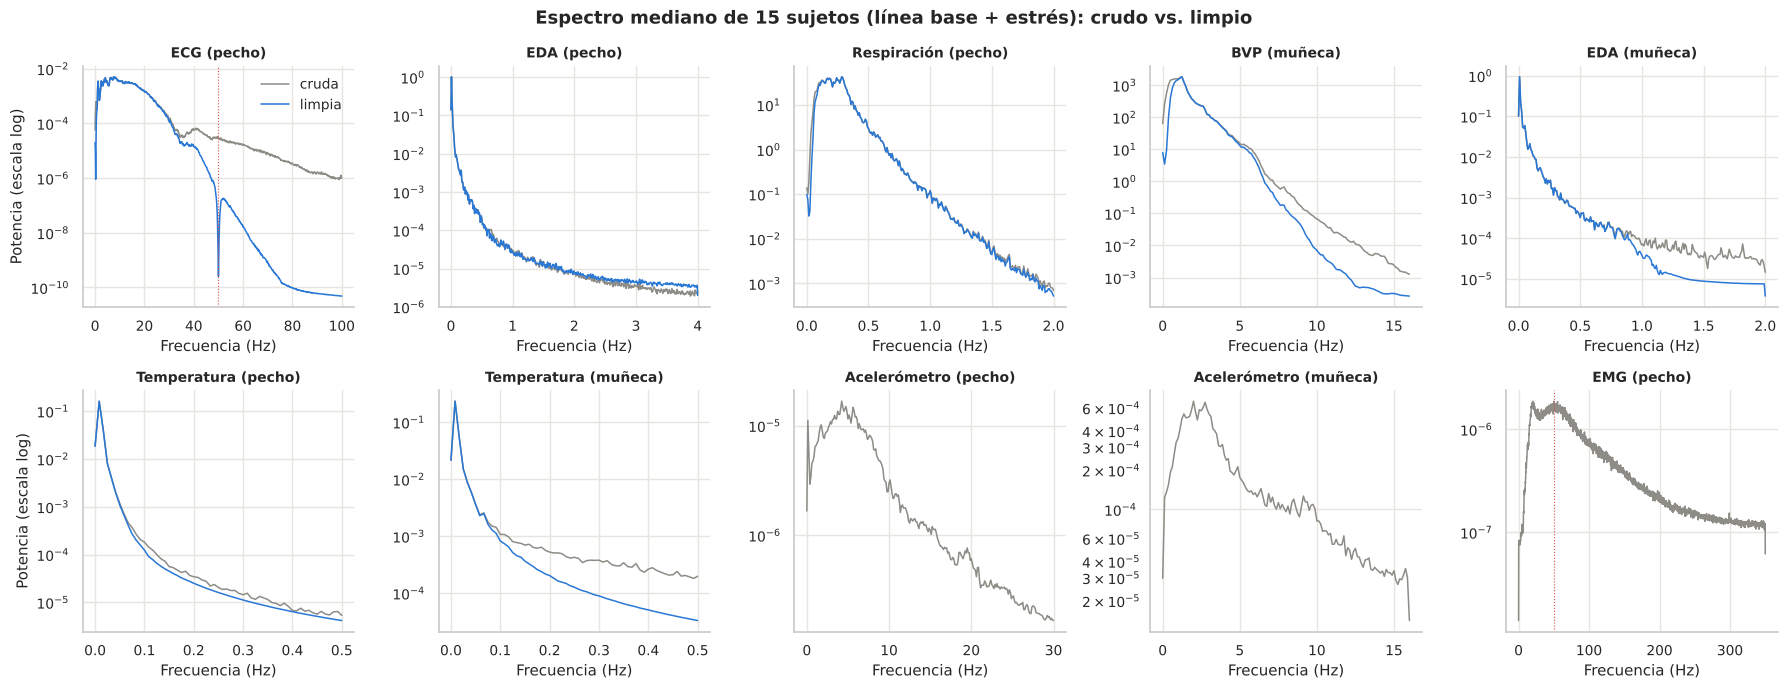

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, key in zip(axes.ravel(), cfg.ALL_SIGNALS):
    for version, color in (("cruda", "#8d8c86"), ("limpia", "#2a78d6")):
        d = psd_df[(psd_df.señal == key) & (psd_df.version == version)]
        if d.empty: continue
        med = d.groupby("f").p.median()
        ax.semilogy(med.index, med.values, color=color, lw=1.1, label=version)
    if key in ("chest_ECG", "chest_EMG"):
        ax.axvline(50, color="#e34948", lw=0.8, ls=":")
    ax.set_title(cfg.SIGNALS[key]["name"]); ax.set_xlabel("Frecuencia (Hz)")
axes[0, 0].legend(frameon=False); axes[0, 0].set_ylabel("Potencia (escala log)"); axes[1, 0].set_ylabel("Potencia (escala log)")
fig.suptitle("Espectro mediano de 15 sujetos (línea base + estrés): crudo vs. limpio", fontweight="bold")
fig.tight_layout(); gr.savefig(fig, "03_espectros_10_senales"); plt.show()

## 3. Antes y después: 20 segundos de cada señal limpia, para cada sujeto
Para **cada uno de los 15 sujetos** graficamos un tramo de 20 s en la condición de **estrés** (a los 2 minutos de
empezar): en gris la señal cruda y en azul la limpia, con los eventos detectados encima. Las figuras se guardan en
`salidas/figuras/03_antes_despues_S{id}.png`.

**Qué buscar:** que la forma de la señal se conserve (los picos siguen en el mismo lugar), que los eventos
caigan donde deben (cada pico R sobre un latido, cada respiración sobre un ciclo) y en qué sujetos el BVP de
muñeca está más deformado por el movimiento.

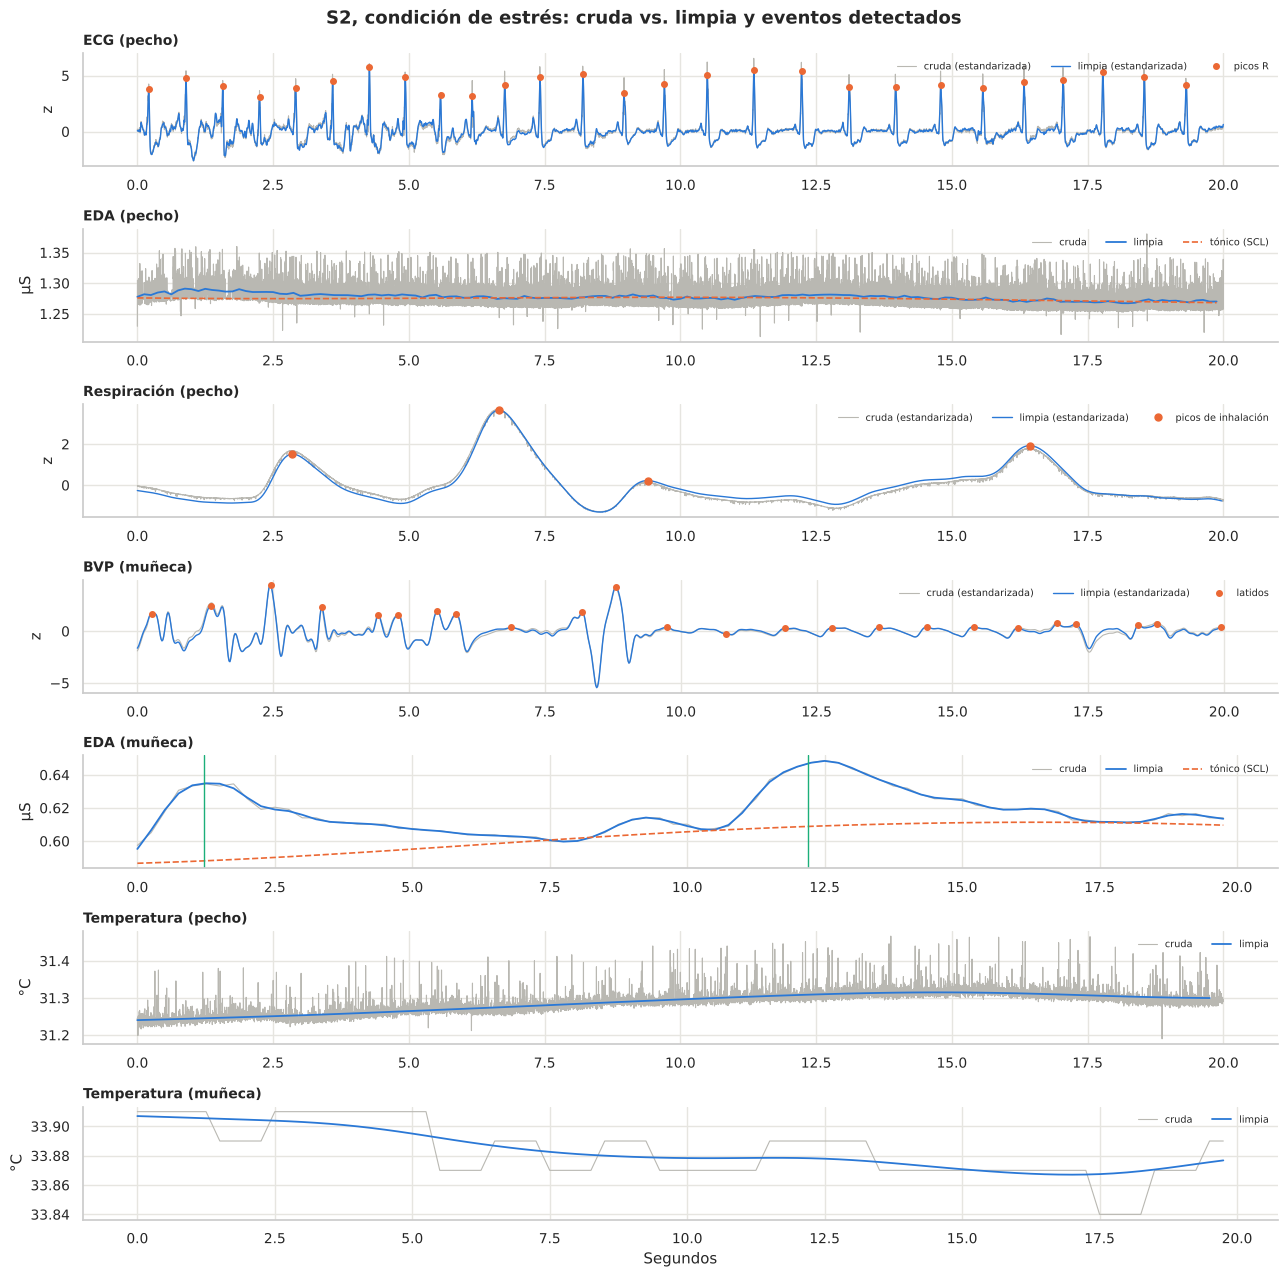

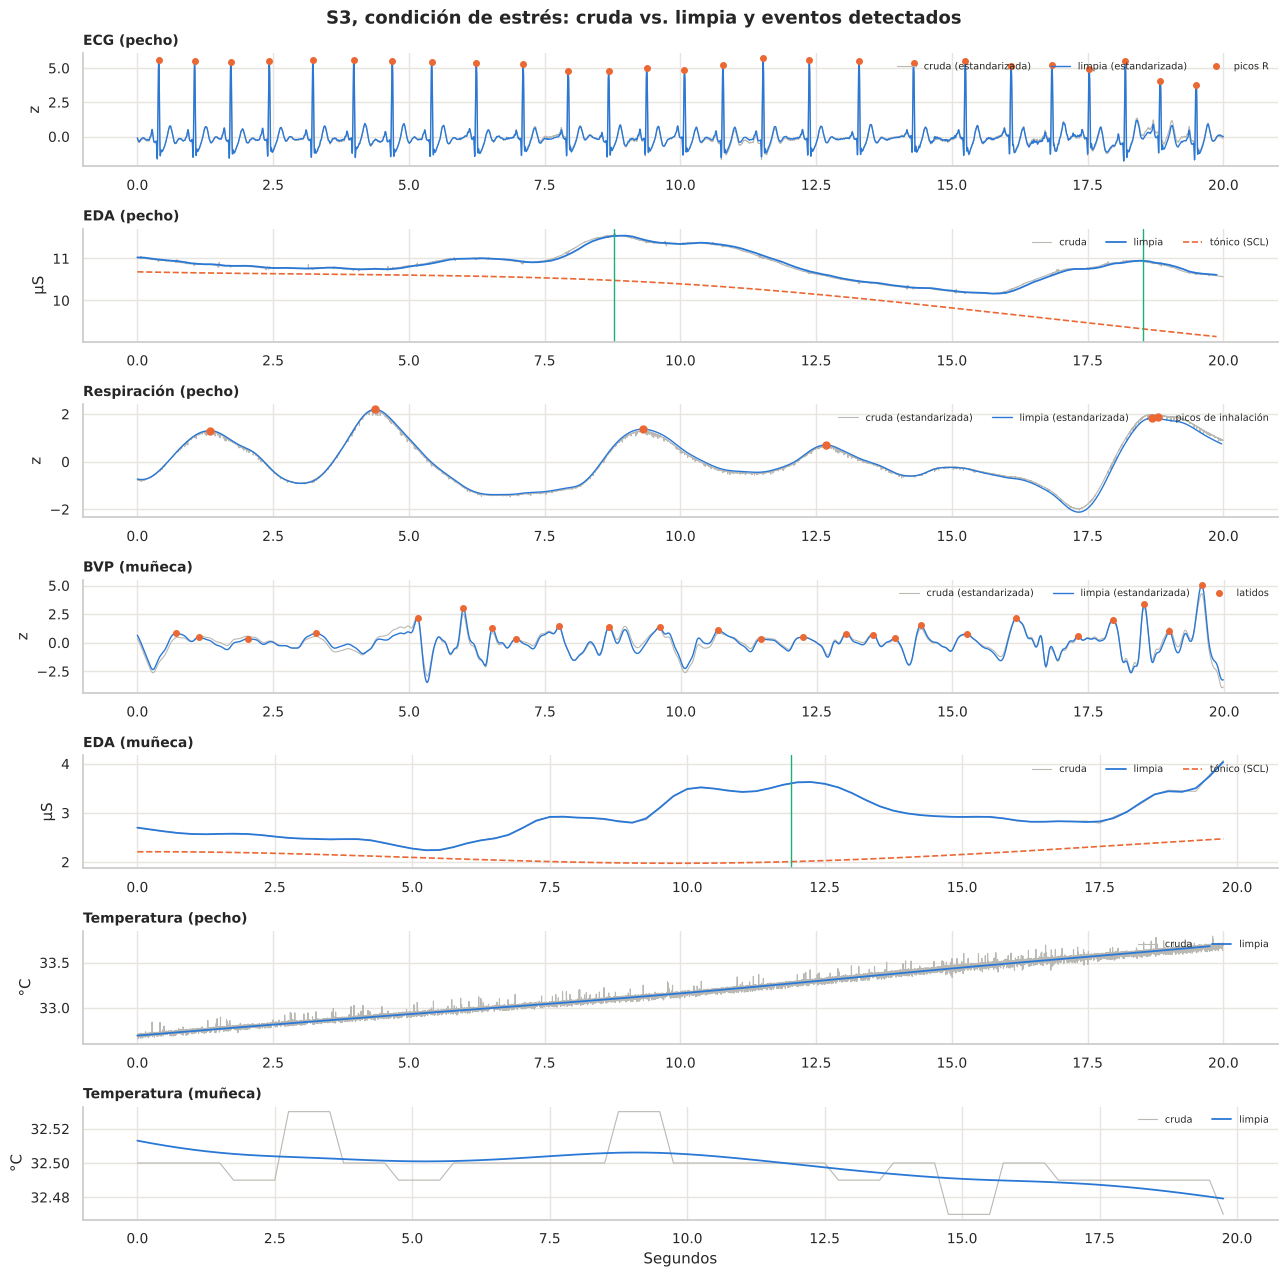

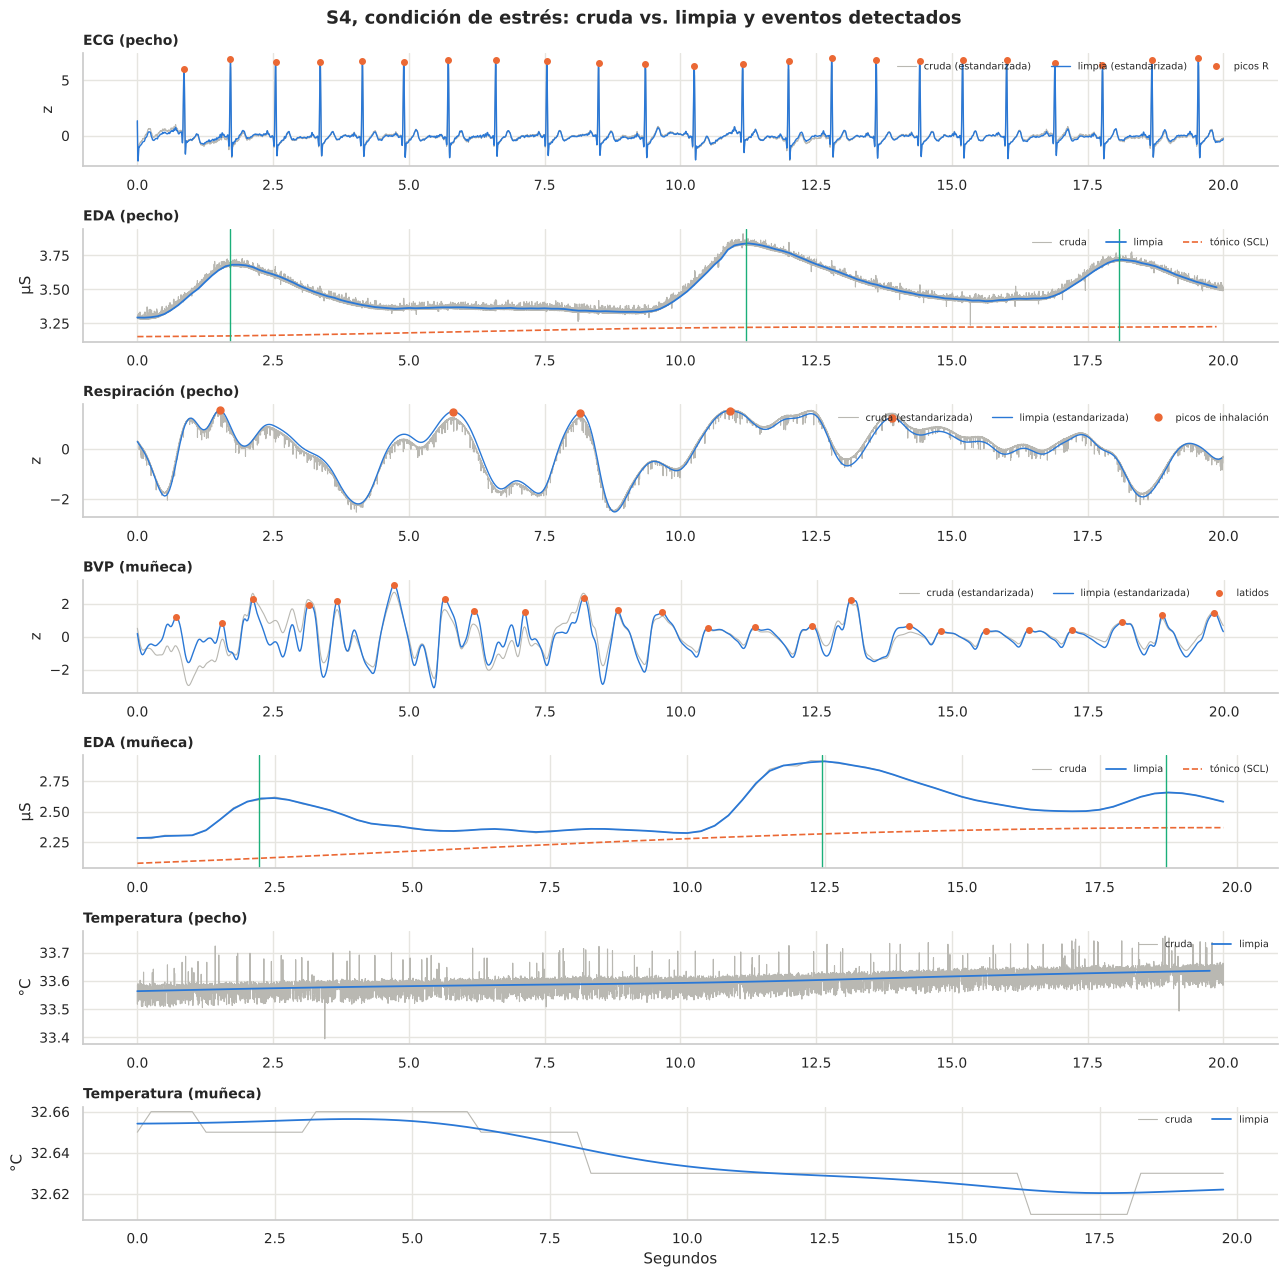

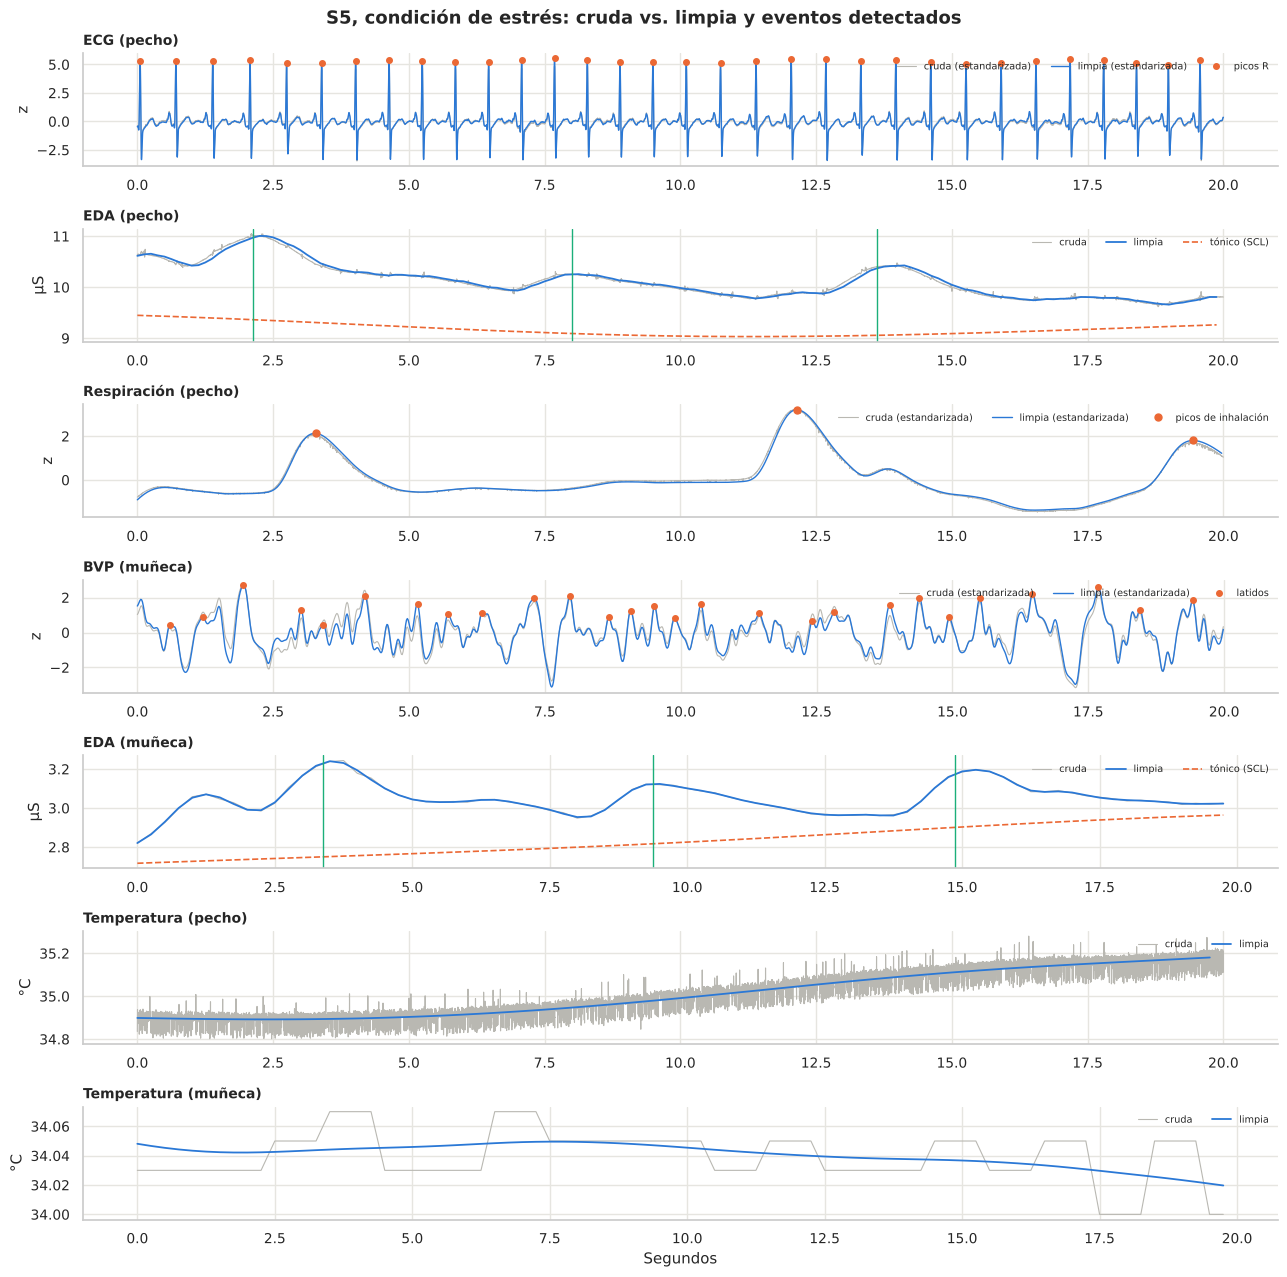

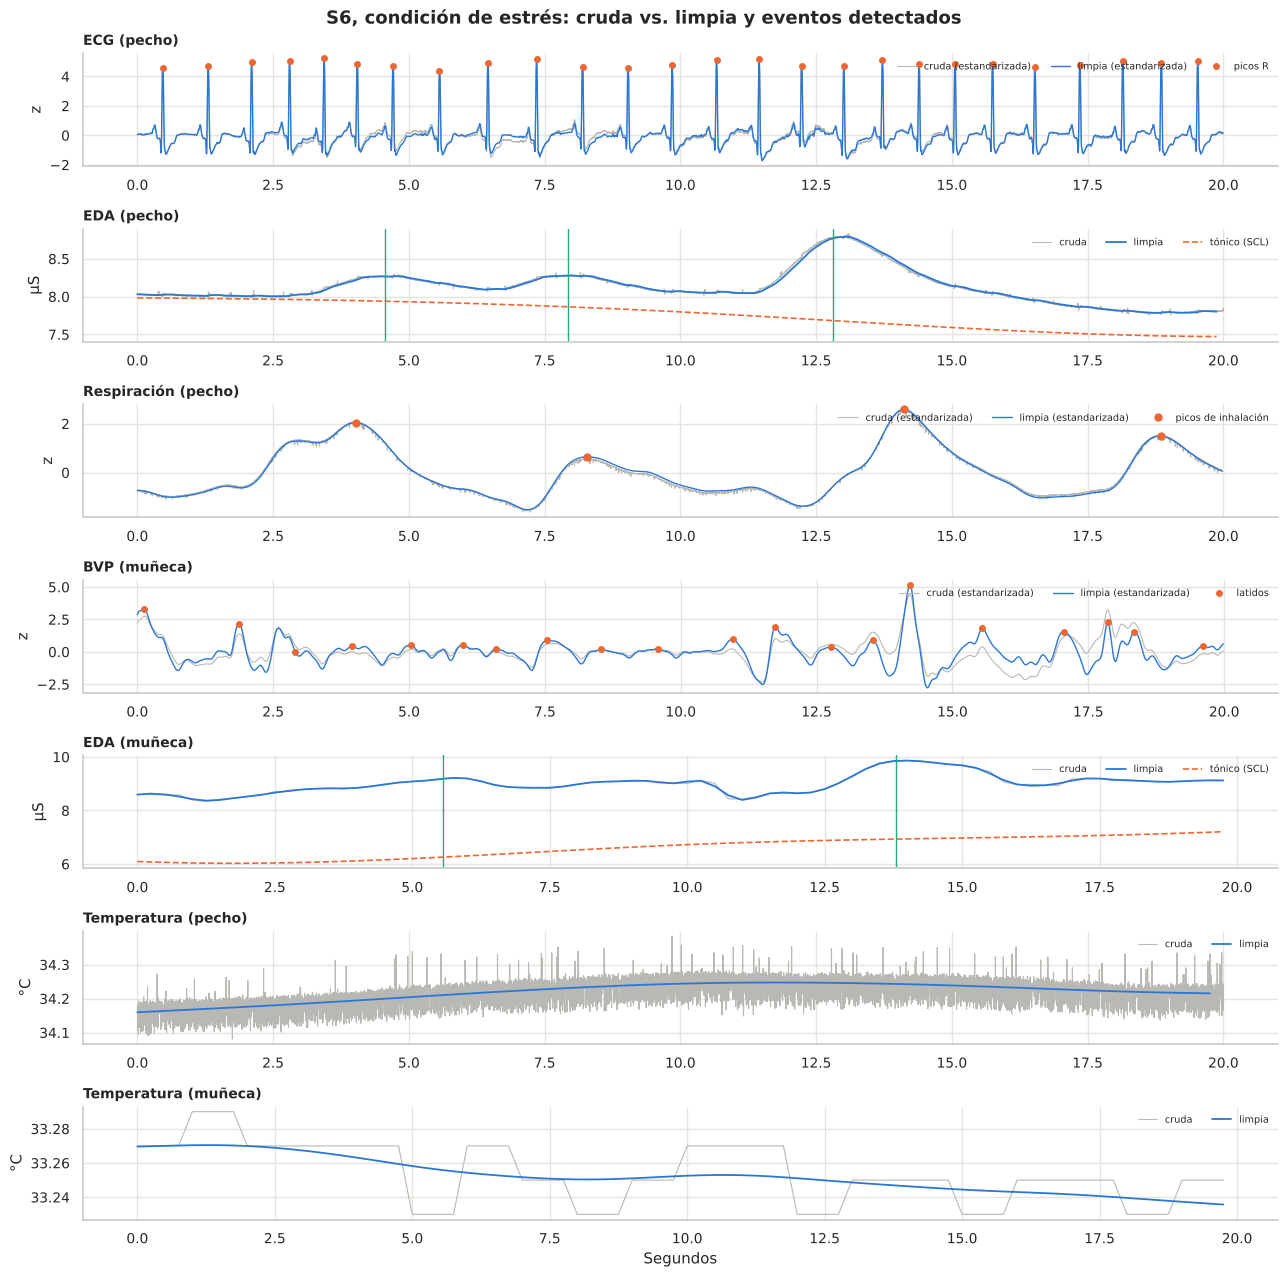

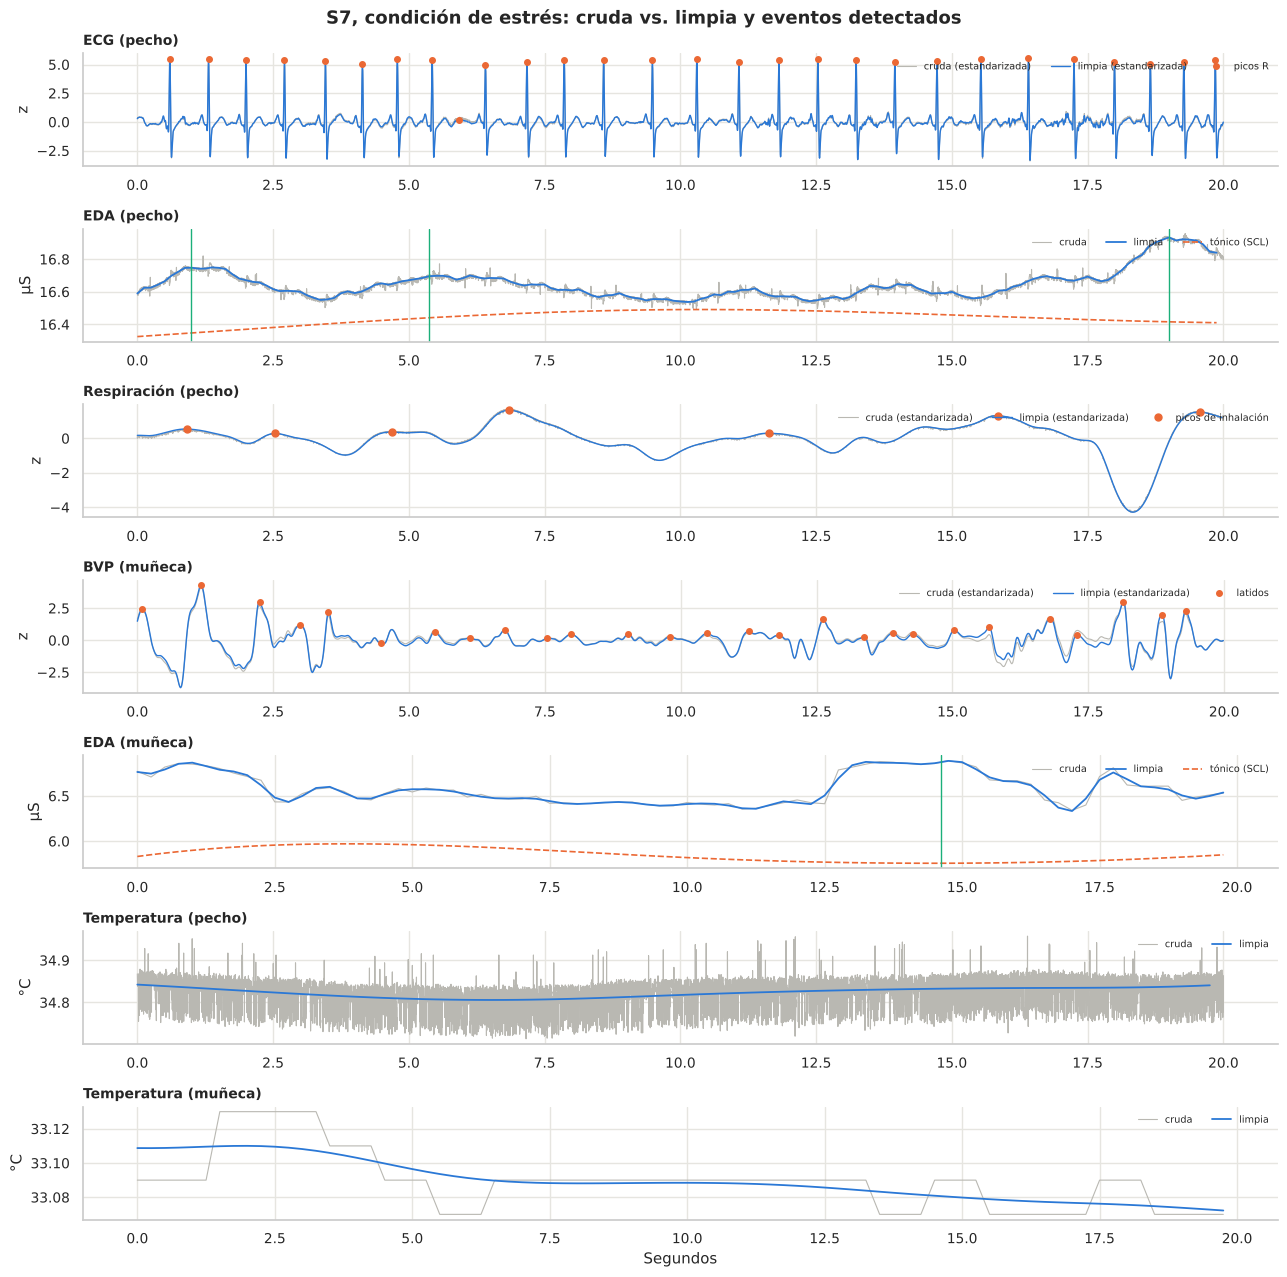

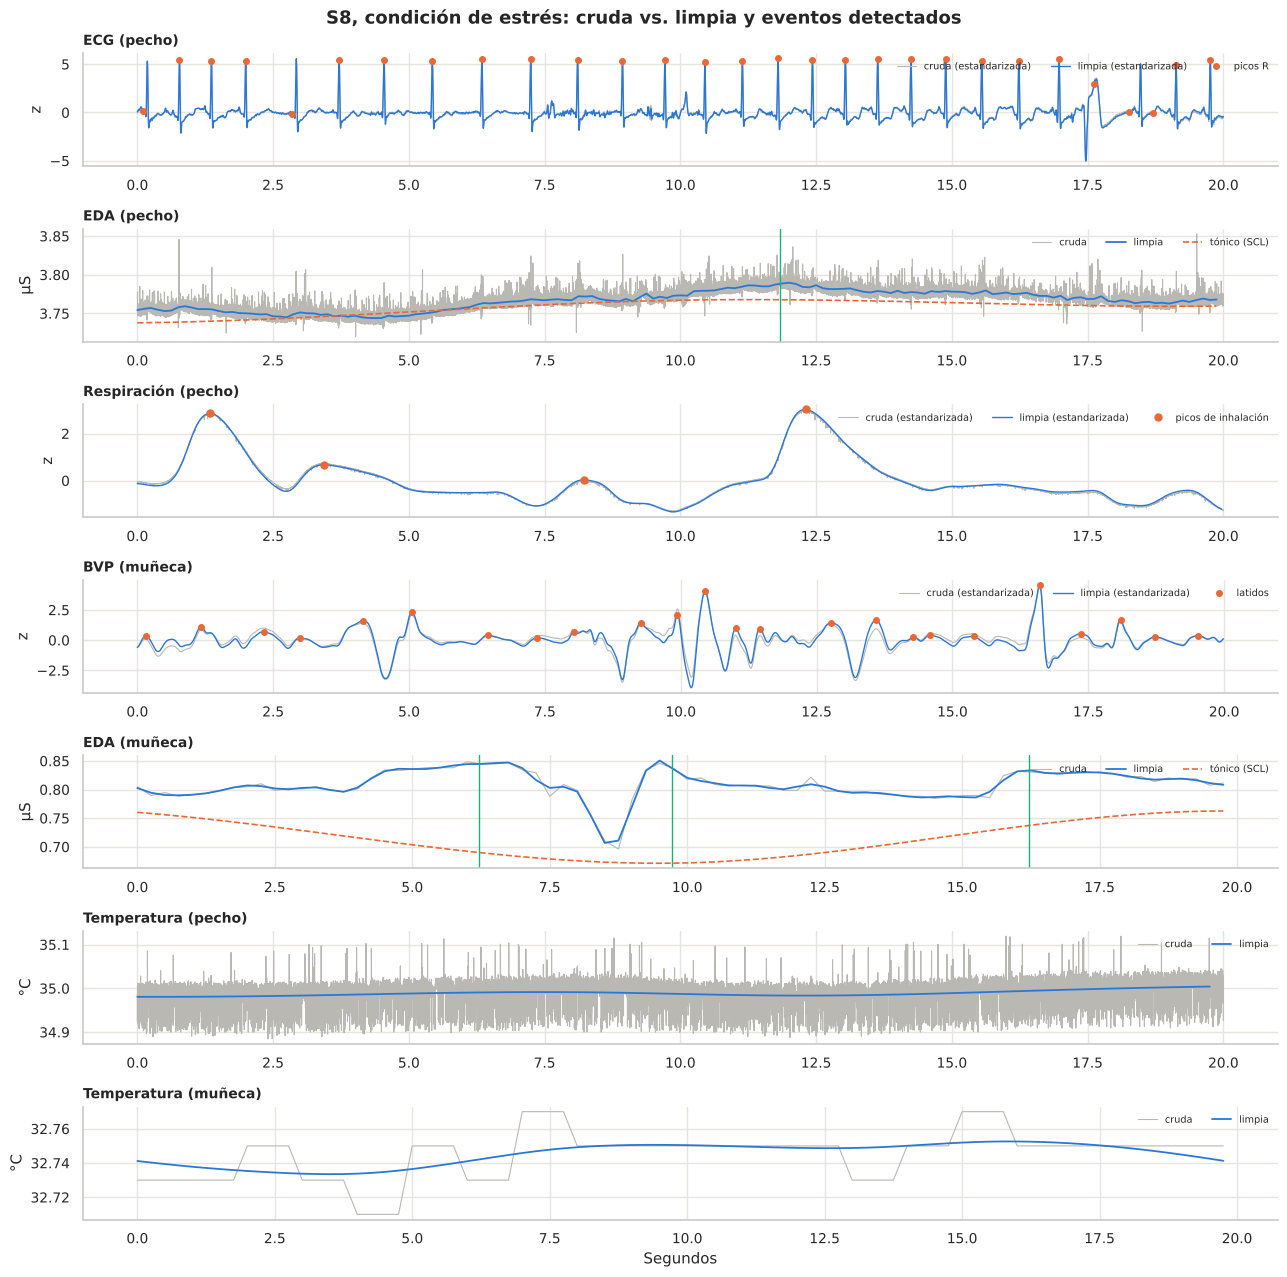

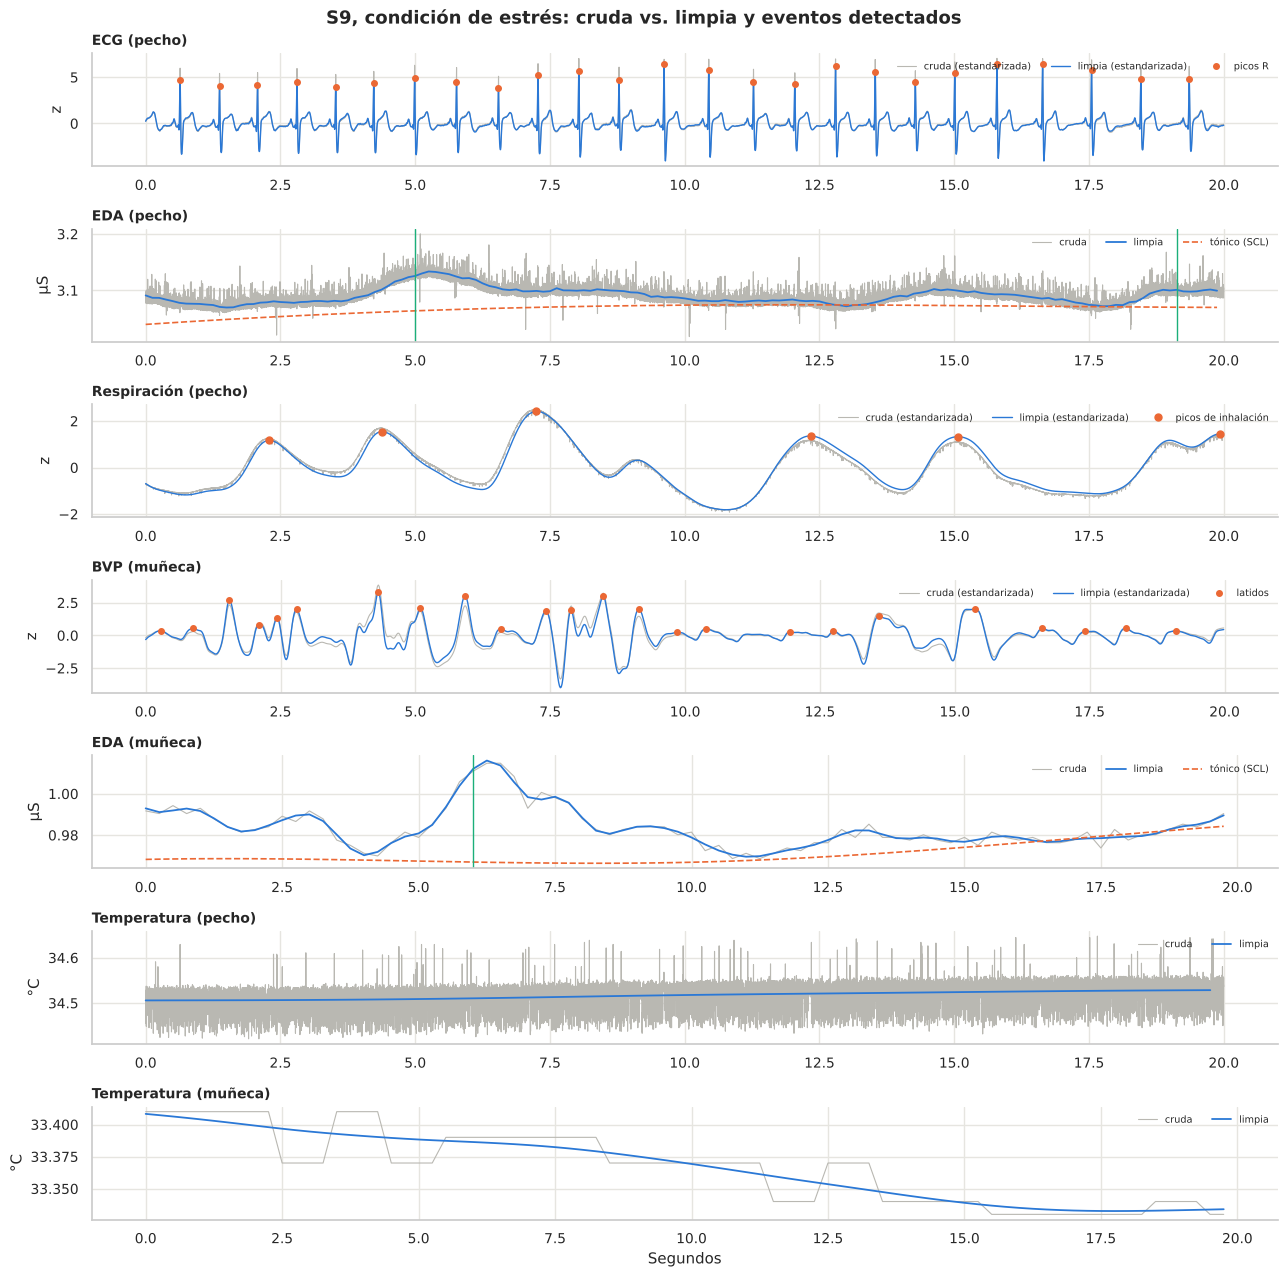

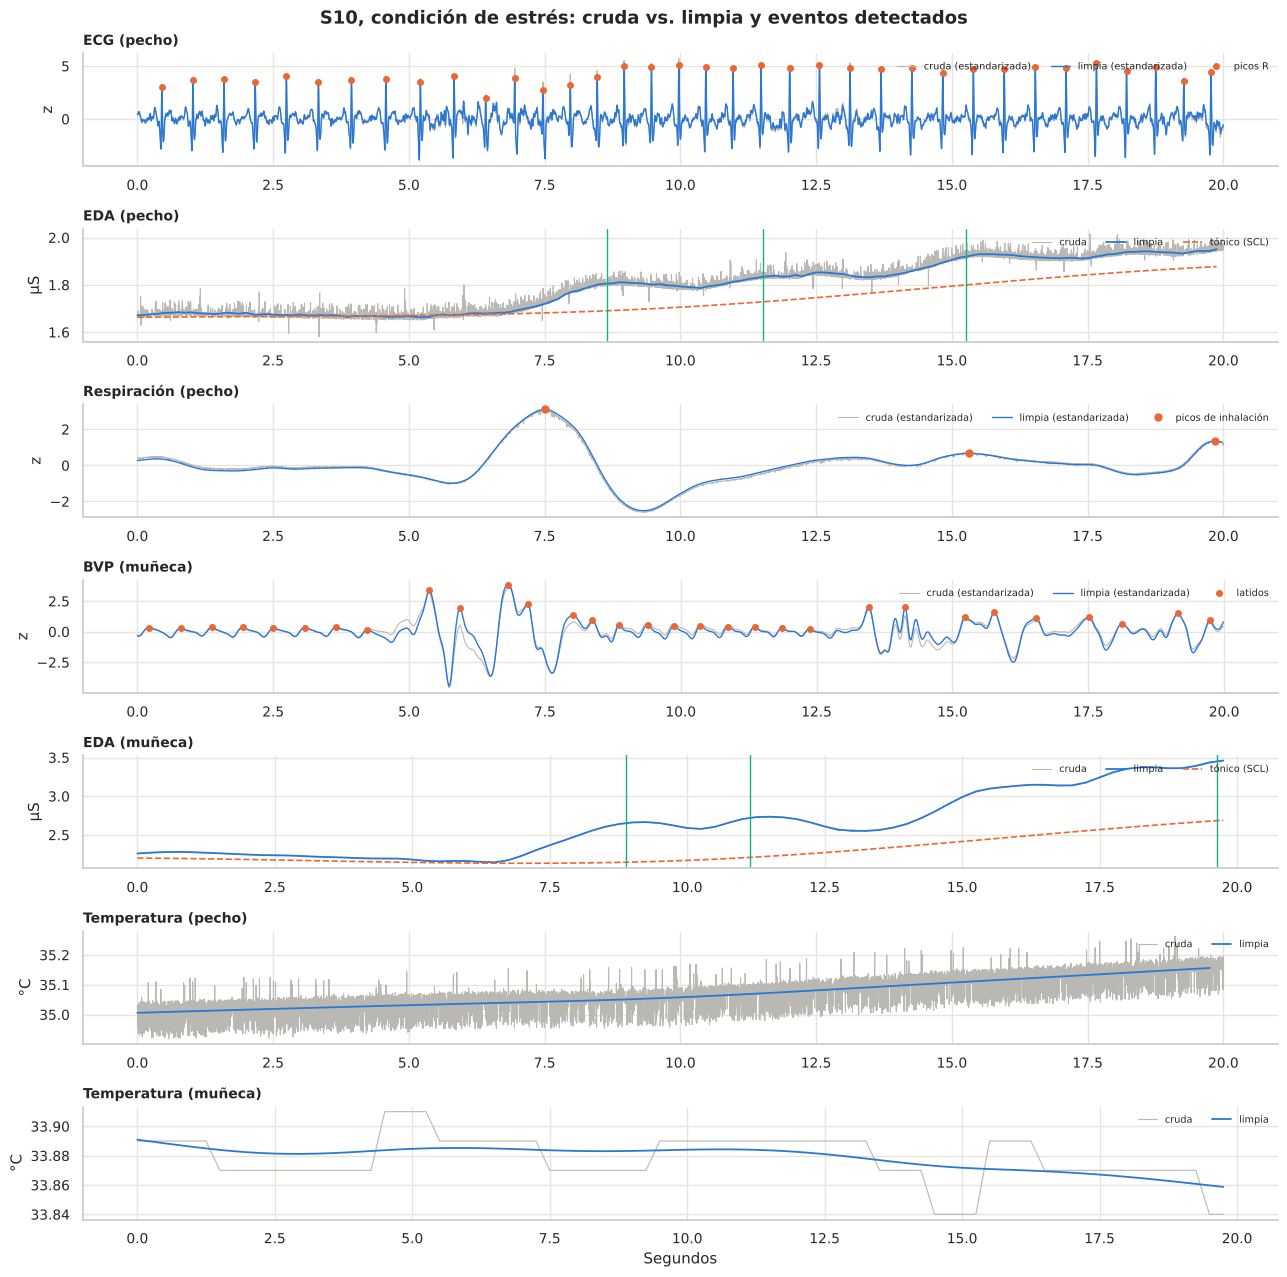

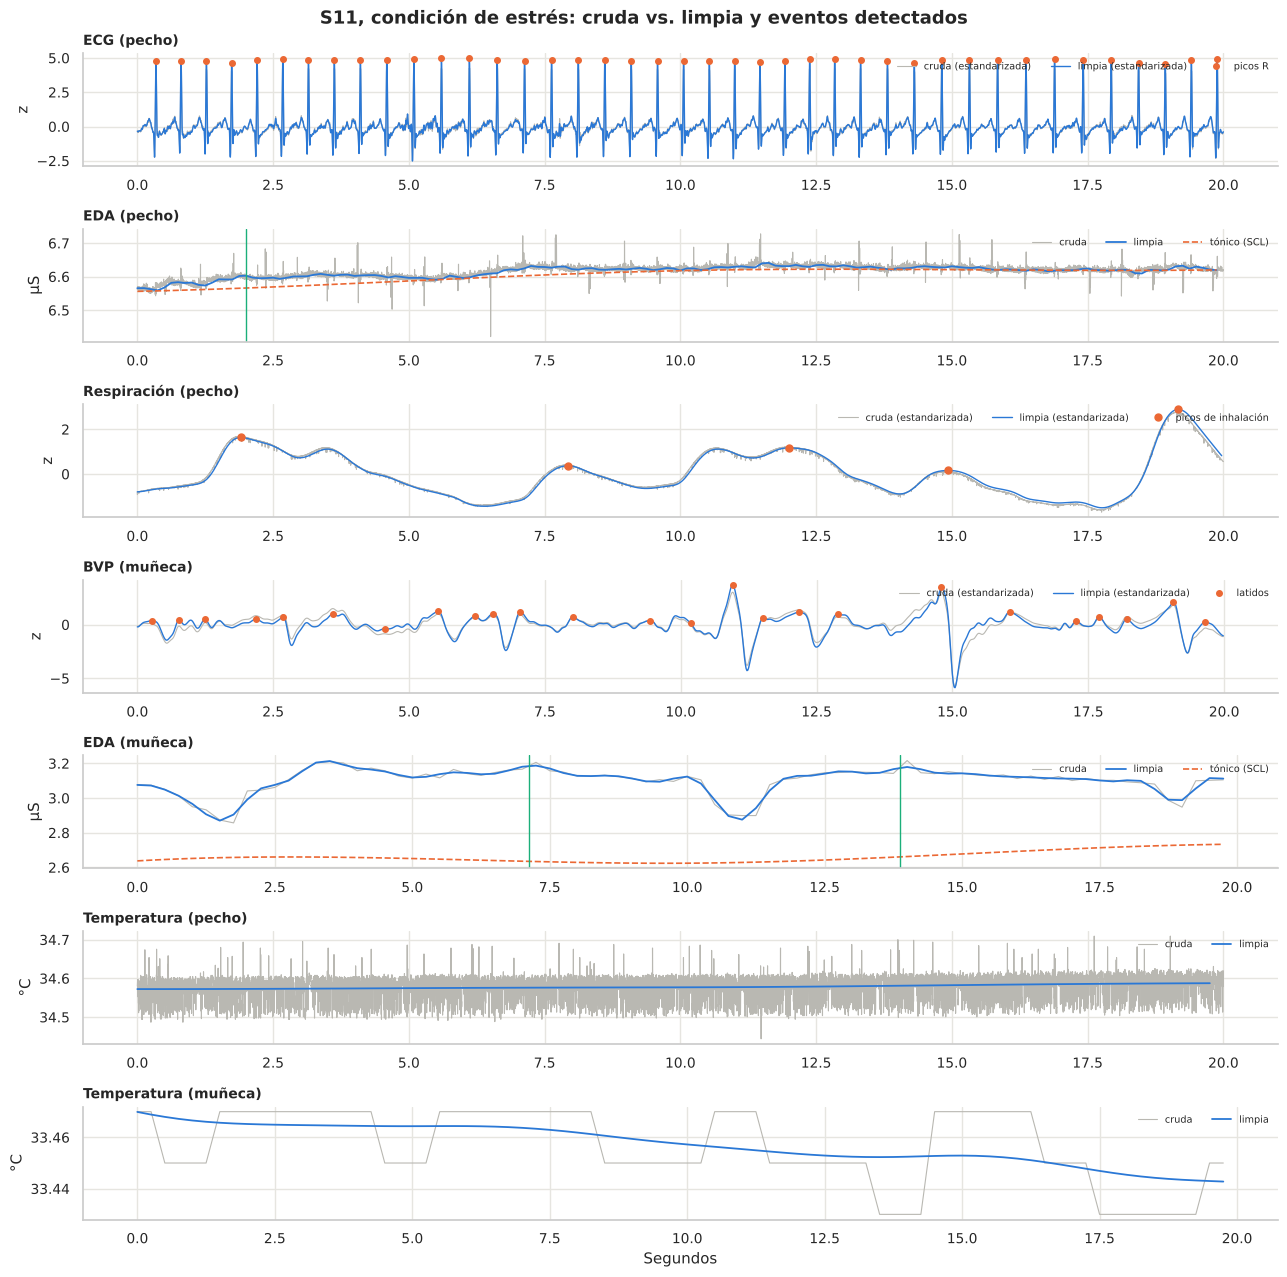

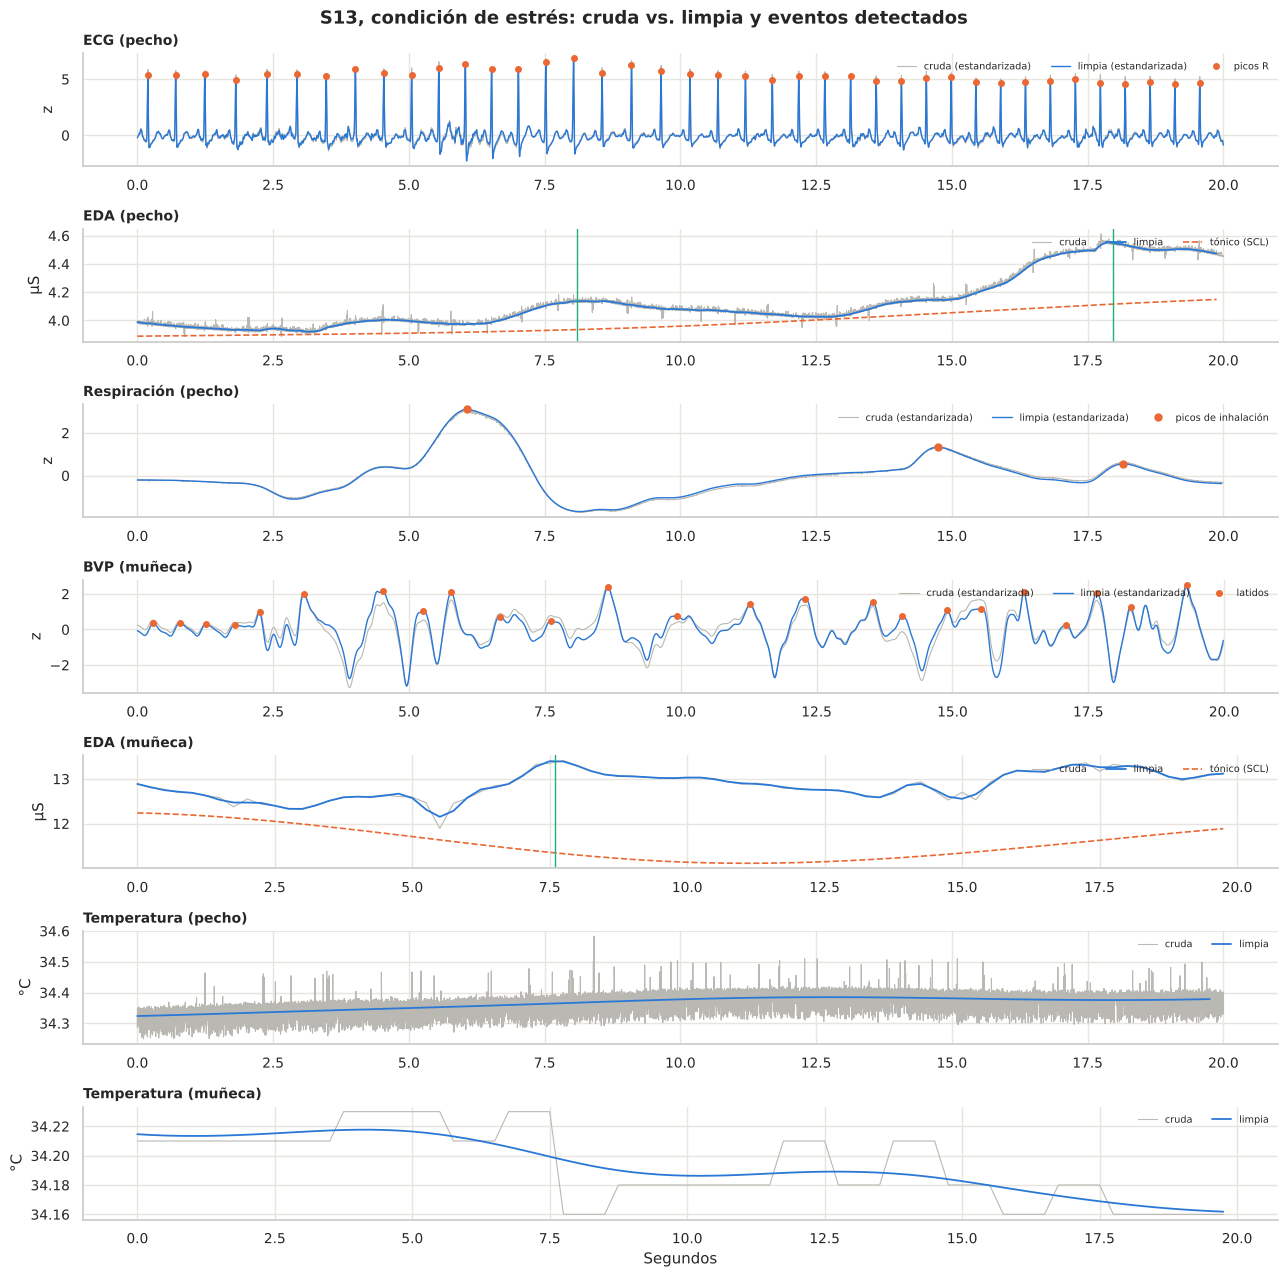

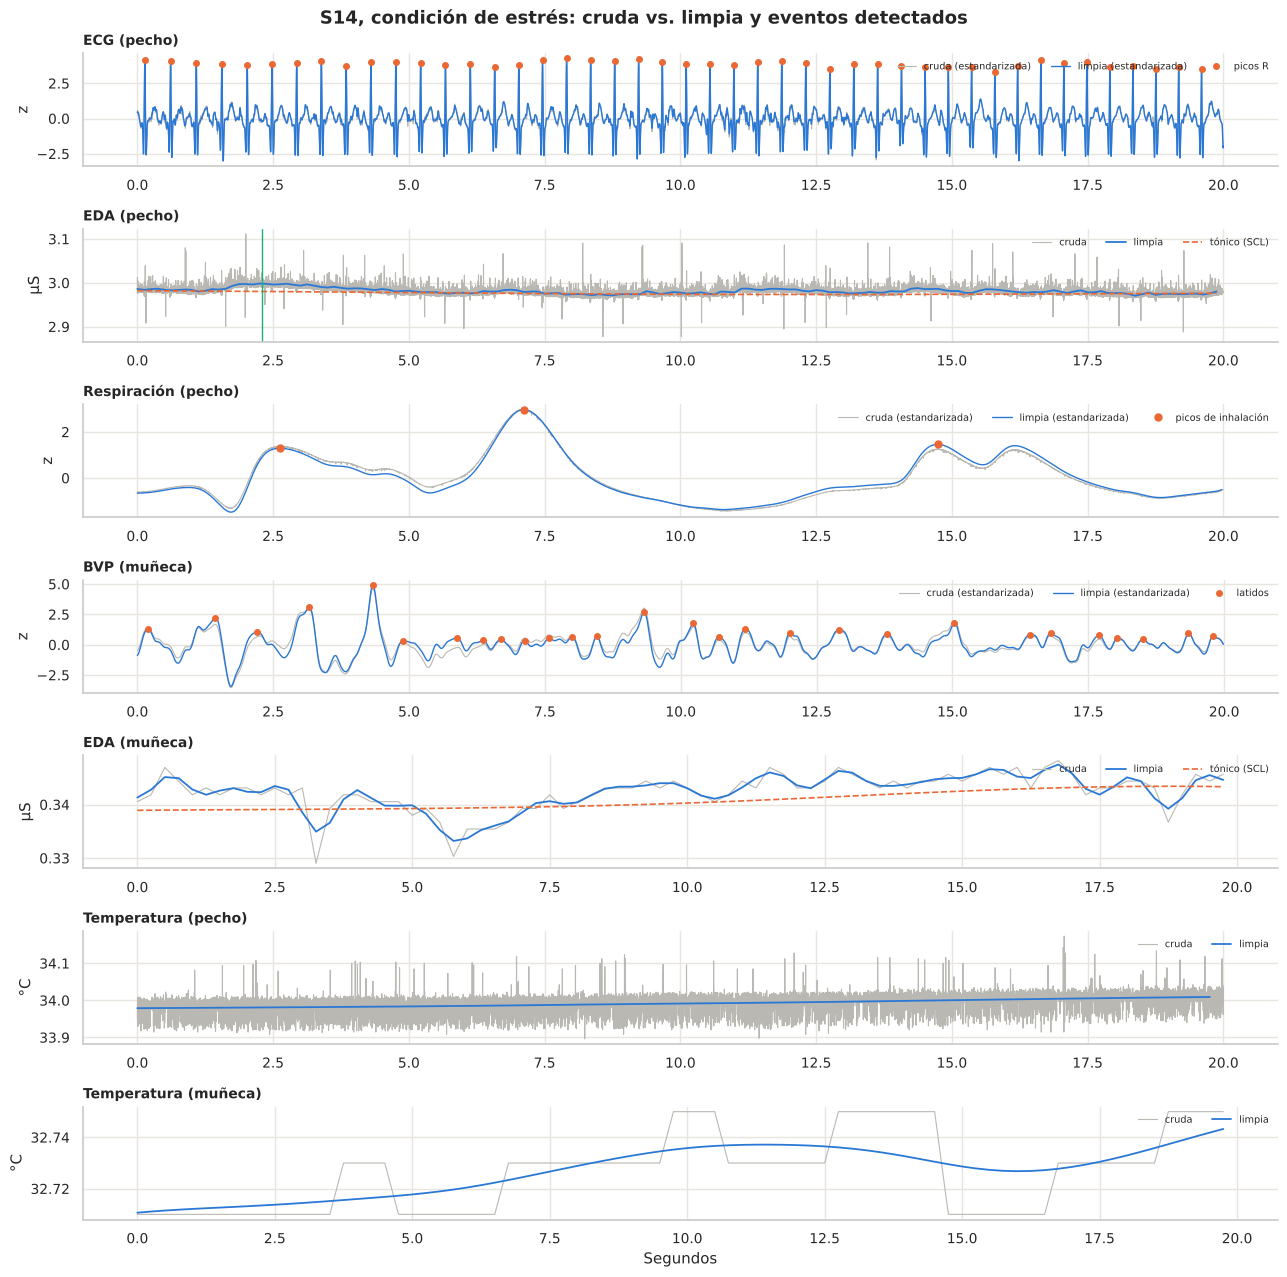

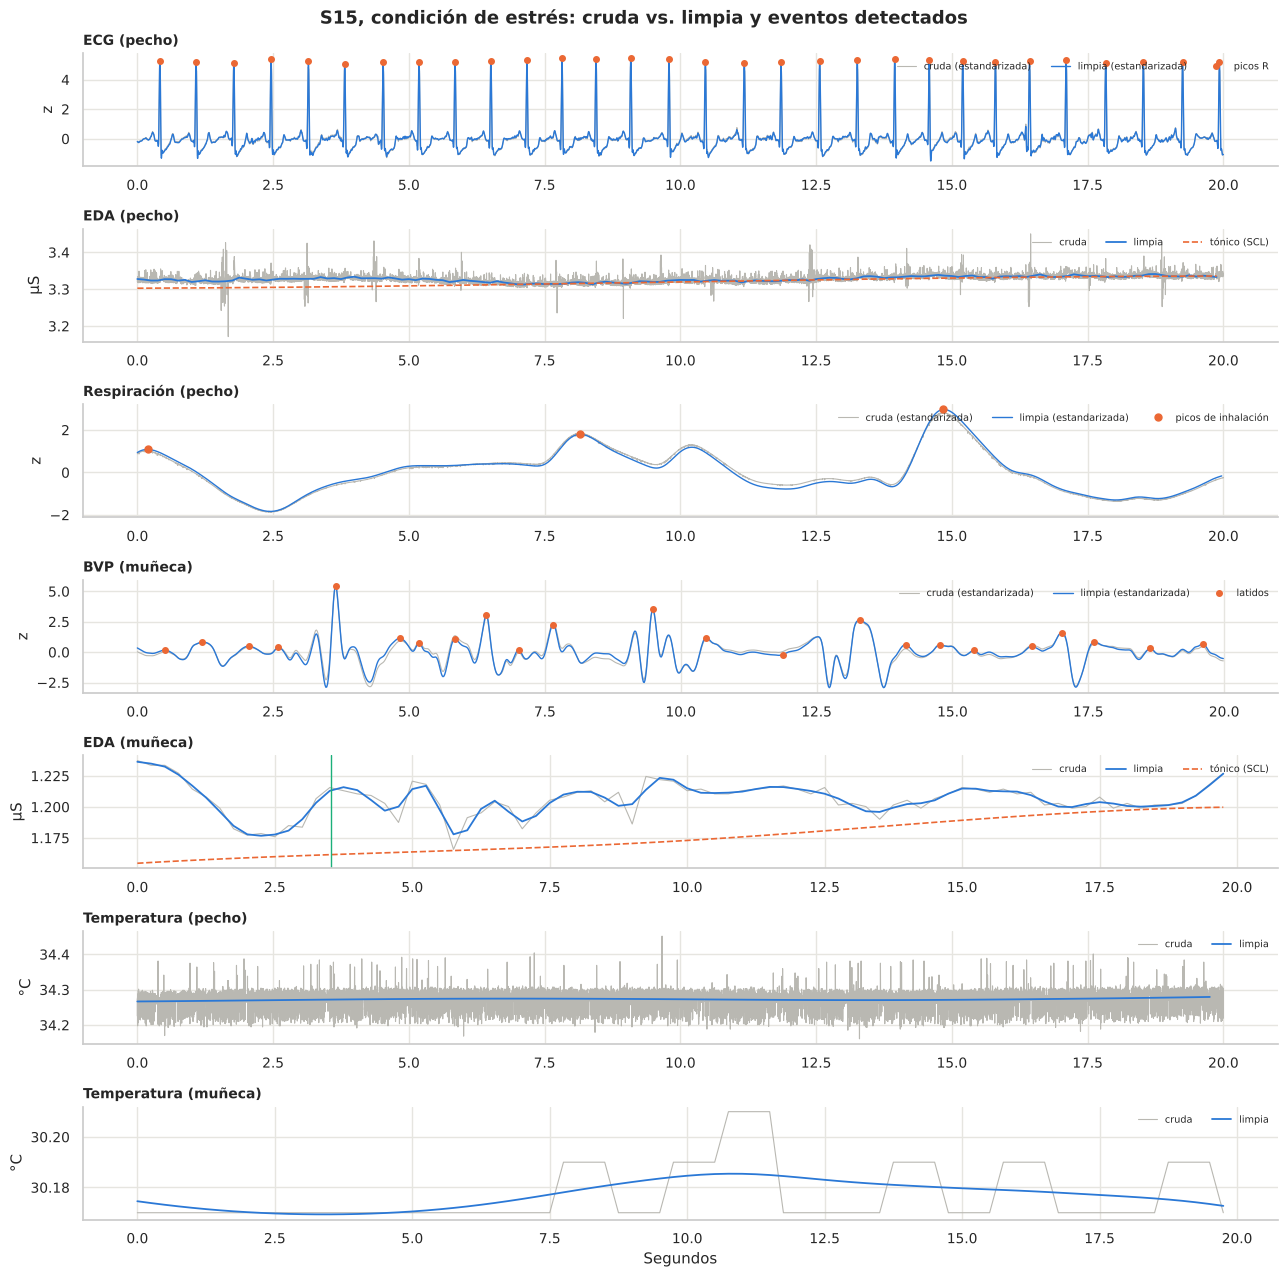

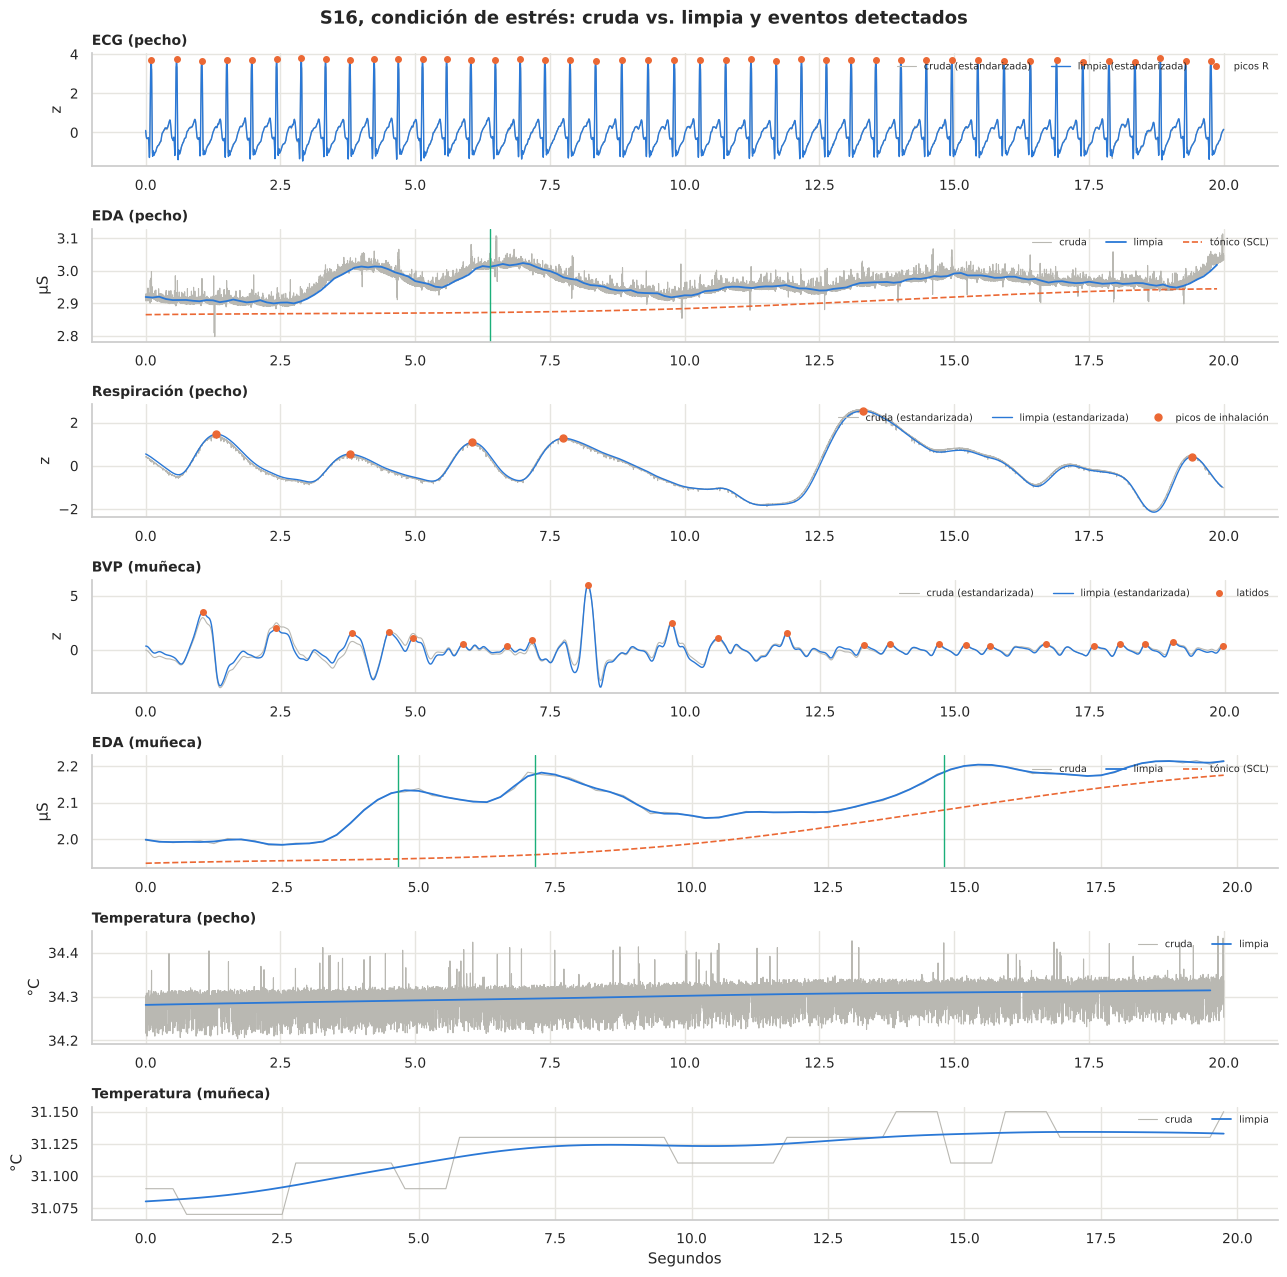

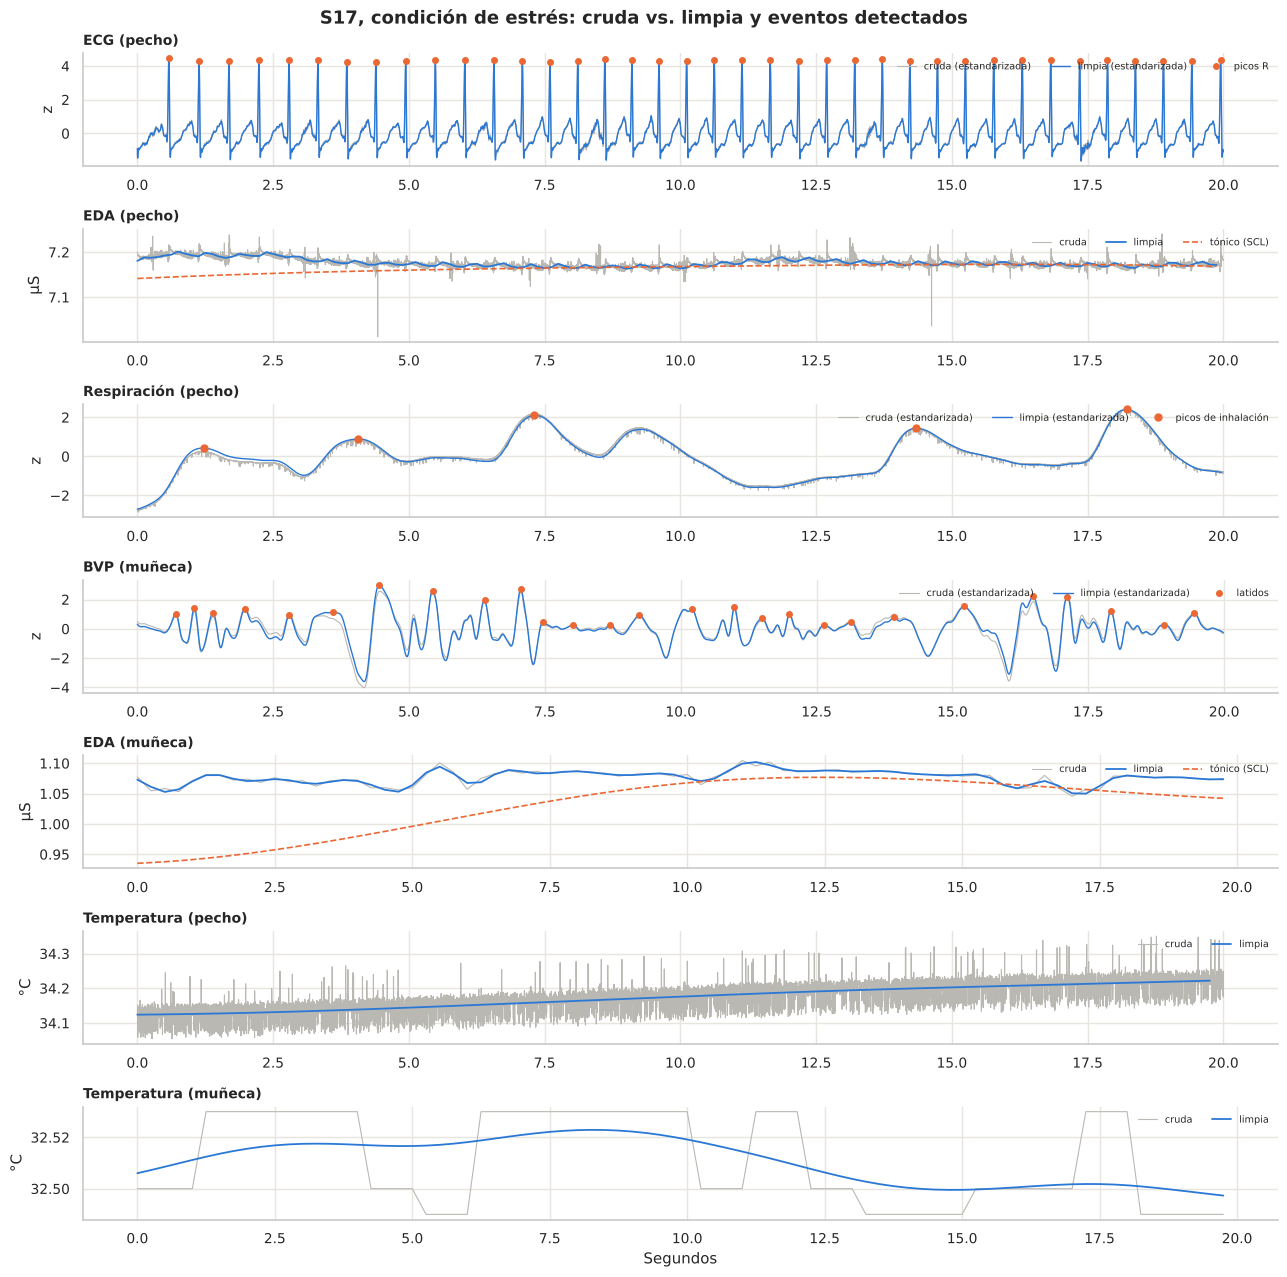

In [4]:
def zscore(v): v = np.asarray(v, float); return (v - np.nanmean(v)) / (np.nanstd(v) + 1e-12)

def antes_despues(sid, T=20):
    data = carga.load_subject(DATA_PATH, sid)
    proc = procesamiento.load_processed(sid)
    b = proc["bloques"]; t0 = b[b.condicion == "stress"].inicio_s.iloc[0] + 120
    fig, axes = plt.subplots(7, 1, figsize=(13, 13))
    for ax, key in zip(axes, cfg.MODEL_SIGNALS):
        raw = carga.get_signal(data, key); fs_r = cfg.SIGNALS[key]["fs"]
        s = proc["señales"][key]; fs_c = s["fs"]
        r = raw[int(t0 * fs_r):int((t0 + T) * fs_r)]; c = np.asarray(s["y"][int(t0 * fs_c):int((t0 + T) * fs_c)], float)
        tr = np.arange(r.size) / fs_r; tc = np.arange(c.size) / fs_c
        if key in ("chest_EDA", "wrist_EDA", "chest_Temp", "wrist_TEMP"):
            ax.plot(tr, r, color="#b9b8b2", lw=0.8, label="cruda"); ax.plot(tc, c, color="#2a78d6", lw=1.3, label="limpia")
            ax.set_ylabel(cfg.SIGNALS[key]["unit"])
            if key in ("chest_EDA", "wrist_EDA"):
                ton = proc["eventos"][key]["tonic"][int(t0 * fs_c):int((t0 + T) * fs_c)]
                ax.plot(tc, ton, color="#eb6834", lw=1.2, ls="--", label="tónico (SCL)")
                scr = proc["eventos"][key]["scr"]; scr = scr[(scr.t_s >= t0) & (scr.t_s < t0 + T)]
                for t in scr.t_s: ax.axvline(t - t0, color="#1baf7a", lw=1)
        else:
            ax.plot(tr, zscore(r), color="#b9b8b2", lw=0.8, label="cruda (estandarizada)")
            ax.plot(tc, zscore(c), color="#2a78d6", lw=1.0, label="limpia (estandarizada)")
            if key == "chest_ECG":
                pk = proc["eventos"][key]["peaks"]; pk = pk[(pk >= t0 * fs_c) & (pk < (t0 + T) * fs_c)] - int(t0 * fs_c)
                ax.plot(pk / fs_c, zscore(c)[pk], "o", color="#eb6834", ms=4, label="picos R")
            if key == "wrist_BVP":
                pk = proc["eventos"][key]["peaks"]; pk = pk[(pk >= t0 * fs_c) & (pk < (t0 + T) * fs_c)] - int(t0 * fs_c)
                ax.plot(pk / fs_c, zscore(c)[pk], "o", color="#eb6834", ms=4, label="latidos")
            if key == "chest_Resp":
                pk = proc["eventos"][key]["peaks"]; pk = pk[(pk >= t0 * fs_c) & (pk < (t0 + T) * fs_c)] - int(t0 * fs_c)
                ax.plot(pk / fs_c, zscore(c)[pk], "o", color="#eb6834", ms=5, label="picos de inhalación")
            ax.set_ylabel("z")
        ax.set_title(cfg.SIGNALS[key]["name"], loc="left"); ax.legend(loc="upper right", fontsize=7, ncol=4, frameon=False)
    axes[-1].set_xlabel("Segundos")
    fig.suptitle(f"S{sid}, condición de estrés: cruda vs. limpia y eventos detectados", fontweight="bold")
    fig.tight_layout(); gr.savefig(fig, f"03_antes_despues_S{sid}"); plt.show()
    plt.close(fig)
    del data, proc; _ = gc.collect()

for sid in SUBJECTS:
    antes_despues(sid)

## 4. Calidad de los eventos por sujeto
- `ecg_corregidos`: latidos corregidos (perdidos, extra o ectópicos) con el algoritmo de Lipponen y Tarvainen (2019).
- `ecg_pct_rr_validos`: % de intervalos RR usables (rango 300–2000 ms, fuera de zonas excluidas y en segmentos
  de ECG con calidad aceptable según Zhao y Zhang 2018).
- `bvp_pct_ibi_validos`: % de intervalos del pulso donde **dos detectores independientes coinciden**. El BVP de muñeca
  es mucho más sensible al movimiento que el ECG, así que se espera un porcentaje menor.
- `resp_pct_ciclos_validos`: % de respiraciones con duración fisiológica (1.5–20 s) y sin datos excluidos.

In [5]:
eventos_resumen.round(1)

,sujeto,ecg_latidos,ecg_corregidos,ecg_pct_rr_validos,ecg_pct_segmentos_inaceptables,bvp_latidos,bvp_corregidos,bvp_pct_ibi_validos,resp_pct_ciclos_validos,eda_pecho_metodo,eda_pecho_scr,eda_muñeca_scr
0,S2,7288,21,96.6,3.0,7035,3,67.0,99.1,cvxeda,34,62
1,S3,6579,20,100.0,0.0,6391,7,61.4,99.9,cvxeda,72,33
2,S4,6959,16,100.0,0.0,6983,5,65.0,98.4,cvxeda,66,58
3,S5,7288,4,100.0,0.0,6299,7,56.5,99.9,cvxeda,83,85
4,S6,8368,10,100.0,0.0,7823,1,64.3,99.7,cvxeda,118,83
5,S7,6265,27,100.0,0.0,5896,11,69.9,98.9,cvxeda,153,77
6,S8,6893,16,100.0,0.0,6350,3,75.9,98.2,cvxeda,52,53
7,S9,6867,5,100.0,0.0,6587,16,75.4,99.6,cvxeda,98,68
8,S10,8426,27,100.0,0.0,7438,137,73.9,99.5,cvxeda,30,27
9,S11,7866,11,100.0,0.0,5742,12,68.1,99.7,cvxeda,114,73


## 5. Movimiento: ¿se mueve más la gente en el estrés?
El índice de movimiento es la variabilidad de la magnitud del acelerómetro en cada segundo (en g; 0 = quieto).
El estrés de WESAD (prueba TSST) consiste en **hablar de pie frente a un panel** y hacer cálculo mental, así que
es probable que haya más movimiento. Si es así, un modelo que use el acelerómetro podría aprender "se mueve = estrés"
en vez de la fisiología. Por eso el acelerómetro se usa solo para marcar ventanas, no como predictor.

También revisamos si el movimiento de la muñeca se relaciona con la pérdida de calidad del BVP.

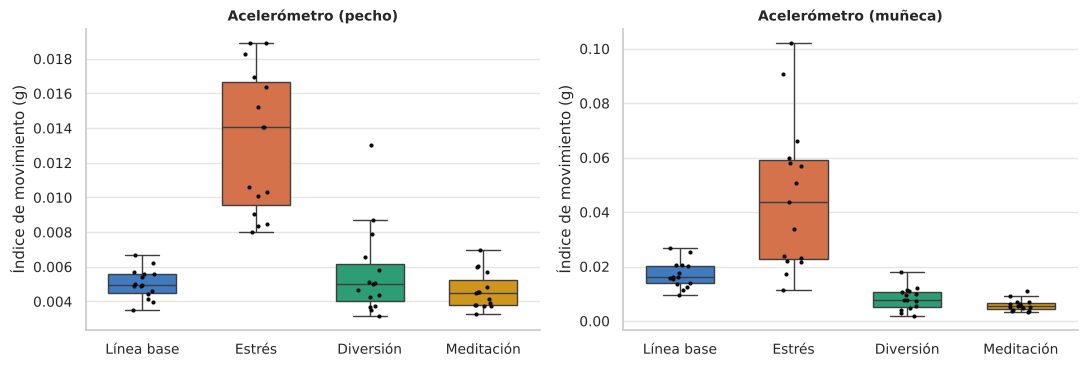

Correlación (por sujeto) entre movimiento de muñeca y calidad del BVP: mediana r = -0.05 (rango -0.20 a 0.11). Negativa = más movimiento, peor BVP.


In [6]:
mov_rows = []
for sid in SUBJECTS:
    proc = procesamiento.load_processed(sid)
    b = proc["bloques"]
    for key in ("chest_ACC", "wrist_ACC"):
        m = proc["movimiento"][key]; t = np.arange(m["y"].size) / m["fs"]
        for cond in cfg.COND_ORDER:
            mask = np.zeros(t.size, bool)
            for _, r in b[b.condicion == cond].iterrows(): mask |= (t >= r.inicio_s) & (t < r.fin_s)
            mov_rows.append(dict(sujeto=f"S{sid}", sensor=key, condicion=cond, movimiento=float(np.mean(m["y"][mask]))))
    q = proc["eventos"]["wrist_BVP"]["acuerdo"]; fsb = proc["señales"]["wrist_BVP"]["fs"]
    mw = proc["movimiento"]["wrist_ACC"]
    n = min(q.size // fsb, mw["y"].size // mw["fs"])
    q_s = q[: n * fsb].reshape(n, fsb).mean(axis=1); m_s = mw["y"][: n * mw["fs"]].reshape(n, mw["fs"]).mean(axis=1)
    mov_rows.append(dict(sujeto=f"S{sid}", sensor="bvp_vs_mov", condicion="todas",
                         movimiento=float(np.corrcoef(m_s, q_s)[0, 1])))
    del proc; _ = gc.collect()
mov = pd.DataFrame(mov_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, key in zip(axes, ("chest_ACC", "wrist_ACC")):
    d = mov[mov.sensor == key]
    sns.boxplot(data=d, x="condicion", y="movimiento", order=cfg.COND_ORDER, palette=gr.COND_COLORS,
                hue="condicion", legend=False, ax=ax, showfliers=False, width=0.6)
    sns.stripplot(data=d, x="condicion", y="movimiento", order=cfg.COND_ORDER, color="#0b0b0b", size=3, ax=ax)
    ax.set_title(cfg.SIGNALS[key]["name"]); ax.set_xlabel(""); ax.set_ylabel("Índice de movimiento (g)")
    ax.set_xticks(range(4), [gr.COND_ES[c] for c in cfg.COND_ORDER])
fig.tight_layout(); gr.savefig(fig, "03_movimiento_por_condicion"); plt.show()

r_bvp = mov[mov.sensor == "bvp_vs_mov"].movimiento
print(f"Correlación (por sujeto) entre movimiento de muñeca y calidad del BVP: mediana r = {r_bvp.median():.2f} "
      f"(rango {r_bvp.min():.2f} a {r_bvp.max():.2f}). Negativa = más movimiento, peor BVP.")

## 📌 Qué encontramos con los datos reales
- **ECG:** el espectro crudo no muestra interferencia de 50 Hz; el filtro quita la deriva lenta (< 0.5 Hz) y el ruido
  por encima de 40 Hz. Se detectan entre 6 265 y 8 426 latidos por sujeto, con 4 a 65 correcciones (menos del 1 %).
  El 100 % de los intervalos RR es válido en 14 sujetos y el 96.6 % en S2.
- **BVP de muñeca:** solo entre el 56 % y el 82 % de los intervalos son confiables (dos detectores coinciden).
  En el ejemplo del estrés se ven pulsos deformados por el movimiento del brazo.
- **Respiración:** más del 98 % de los ciclos son válidos en todos los sujetos.
- **EDA:** la descomposición con cvxEDA funcionó en todos los sujetos y bloques (no hizo falta el método de respaldo).
- **Movimiento:** los participantes se mueven claramente más en el estrés (pecho y muñeca). Es la razón para no usar
  el acelerómetro como predictor.

## Resumen de este notebook
- Señales limpias y eventos de los 15 sujetos en `salidas/limpias/`.
- Calidad de eventos en `salidas/tablas/eventos_resumen.csv`.
- Siguiente paso: **04_marcadores_y_variabilidad**, donde se ve si el estrés se nota en cada señal.